# 05 · Robustness, defense, quality slices, Grad-CAM, external test (FaceShifter)

Everything the final report still needs, in one notebook. Run the cells **in order** on a **T4 GPU**
(about 60–75 min in total). Each cell saves its result to Drive, so after a disconnect you only rerun
SETUP, cells 1–2 and the cell that was interrupted.

| Cell | What | Output in Drive | Time |
|---|---|---|---|
| 3 | **Defense**: train `mnv2_robust` = `mnv2_v1` + perturbation-augmented training (JPEG, downscaling, blur; **noise is held out**), evaluate on val/test | `runs/mnv2_robust/` | ~15 min |
| 4 | **Attack test**: test split under 9 post-processing attacks, both models, at their validation thresholds | `runs/<run>/eval/robustness_test.csv` | ~20 min |
| 5 | **Quality slices**: false alarms and misses per brightness / contrast / sharpness tertile | `report/quality_slices.csv` | ~2 min |
| 6 | **Grad-CAM**: where the model looks (errors, correct detections, average map per method) | `report/gradcam_*.png` | ~3 min |
| 7 | **External test**: FaceShifter test split (never used in training), downloaded with the official script | `cache/crops_v1_faceshifter/`, `runs/<run>/eval/external_FaceShifter.json` | ~15 min |
| 8 | **Demo videos**: chosen test videos (+ FaceShifter) for notebook 06 | `demo_videos/` | ~2 min |
| 9 | **Pack results** for the report (no weights, no videos) | `results_final.zip` | <1 min |

Requires: notebooks 01–03 done (cache `crops_v1`, runs `mnv2_v1`, `mnv2_gru_v1`, `mnv2_lomo_FS` evaluated),
and the download script in Drive.

In [1]:
#@title 0 · Setup (run after every restart)
DRIVE_ROOT = "/content/drive/MyDrive/IS665_Deepfake"  #@param {type:"string"}
REPO_URL = "https://github.com/payelsarkarr/is665-team6-deepfake-recognition"  #@param {type:"string"}
from google.colab import drive
drive.mount("/content/drive")
import os, sys, subprocess
os.makedirs(DRIVE_ROOT, exist_ok=True)
REPO = "/content/repo"
if os.path.exists(REPO):
    subprocess.run(["git", "-C", REPO, "pull", "-q"], check=True)       # newest code from GitHub
else:
    subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, REPO], check=True)
sys.path.insert(0, f"{REPO}/src")
import cv2
if not hasattr(cv2, "CascadeClassifier"):
    !pip -q install "opencv-python-headless<5"
    print("OpenCV 4 installed -> Runtime > Restart session, then run this cell again.")
META = "/content/FaceForensics/dataset"            # official split files
if not os.path.exists(META):
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/ondyari/FaceForensics.git", "/content/FaceForensics"], check=True)
import importlib, ffpp
for m in ["data", "crops", "dataset", "models", "metrics", "train", "evaluate", "download", "infer", "perturb", "xai", "robustness"]:
    importlib.reload(importlib.import_module(f"ffpp.{m}"))
print("code:", subprocess.run(["git", "-C", REPO, "log", "-1", "--format=%h %s"], capture_output=True, text=True).stdout.strip())

Mounted at /content/drive
code: 27bf2e3 Add robustness, defense, Grad-CAM, FaceShifter test and demo app


In [2]:
#@title 1 · Settings
CACHE_VERSION = "crops_v1"  #@param {type:"string"}
BASE_RUN = "mnv2_v1"  #@param {type:"string"}
ROBUST_RUN = "mnv2_robust"  #@param {type:"string"}
ROBUST_AUG = 0.5  #@param {type:"number"}
ATTACK_RUNS = "mnv2_v1, mnv2_robust"  #@param {type:"string"}
#@markdown (add mnv2_gru_v1 above if there is time: +25 min)
EXTERNAL_RUNS = "mnv2_v1, mnv2_robust, mnv2_gru_v1, mnv2_lomo_FS"  #@param {type:"string"}
SCRIPT = f"{DRIVE_ROOT}/faceforensics_download_v4.py"
RUNS_DIR = f"{DRIVE_ROOT}/runs"
REPORT_DIR = f"{DRIVE_ROOT}/report"; os.makedirs(REPORT_DIR, exist_ok=True)
EXT_CACHE = f"{DRIVE_ROOT}/cache/{CACHE_VERSION}_faceshifter"
DEMO_DIR = f"{DRIVE_ROOT}/demo_videos"
split_runs = lambda s: [r.strip() for r in s.split(",") if r.strip()]
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - switch the runtime to T4 GPU")

GPU: Tesla T4


In [3]:
#@title 2 · Copy the face-clip cache to the Colab disk (fast reads)
from ffpp.dataset import copy_cache_local
LOCAL_CACHE = str(copy_cache_local(f"{DRIVE_ROOT}/cache/{CACHE_VERSION}", f"/content/cache/{CACHE_VERSION}"))

cache in /content/cache/crops_v1: 4999 files copied


In [4]:
#@title 3 · Defense: train the perturbation-augmented model and evaluate it (resumes after a disconnect)
import json
from ffpp.train import train
from ffpp.evaluate import evaluate_run
base_cfg = json.load(open(f"{RUNS_DIR}/{BASE_RUN}/config.json"))
cfg = {**base_cfg, "run_name": ROBUST_RUN, "robust_aug": ROBUST_AUG, "robust_kinds": ["jpeg", "down", "blur"],
       "num_workers": 2}
print("same settings as", BASE_RUN, "+ robust_aug", ROBUST_AUG, "(JPEG, downscaling, blur; noise held out)")
hist = train(cfg, LOCAL_CACHE, RUNS_DIR)
res = evaluate_run(f"{RUNS_DIR}/{ROBUST_RUN}", LOCAL_CACHE)
t = res["test"]["at_val_threshold"]
print(f"{ROBUST_RUN}: test ROC-AUC {res['test']['at_0_5']['roc_auc']:.3f} | recall {t['recall']:.3f} | FPR {t['fpr']:.3f}")

same settings as mnv2_v1 + robust_aug 0.5 (JPEG, downscaling, blur; noise held out)
train: 3599 videos (720 real, 2879 fake) | val: 655 videos | mode=frame, batch=64, device=cuda
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 188MB/s]


mnv2: 2.23 M parameters
  epoch 1 batch 100/224 loss 0.7015
  epoch 1 batch 200/224 loss 0.6942
epoch 1/8: loss 0.6952 | val ROC-AUC 0.5613 recall 0.448 FPR 0.356 | 1.4 min  * best, saved
  epoch 2 batch 100/224 loss 0.6684
  epoch 2 batch 200/224 loss 0.6337
epoch 2/8: loss 0.6268 | val ROC-AUC 0.9098 recall 0.869 FPR 0.259 | 1.3 min  * best, saved
  epoch 3 batch 100/224 loss 0.5115
  epoch 3 batch 200/224 loss 0.4988
epoch 3/8: loss 0.4980 | val ROC-AUC 0.9510 recall 0.863 FPR 0.081 | 1.4 min  * best, saved
  epoch 4 batch 100/224 loss 0.4355
  epoch 4 batch 200/224 loss 0.4357
epoch 4/8: loss 0.4320 | val ROC-AUC 0.9573 recall 0.898 FPR 0.096 | 1.3 min  * best, saved
  epoch 5 batch 100/224 loss 0.4006
  epoch 5 batch 200/224 loss 0.3927
epoch 5/8: loss 0.3903 | val ROC-AUC 0.9567 recall 0.896 FPR 0.111 | 1.4 min
  epoch 6 batch 100/224 loss 0.3667
  epoch 6 batch 200/224 loss 0.3552
epoch 6/8: loss 0.3579 | val ROC-AUC 0.9677 recall 0.921 FPR 0.081 | 1.3 min  * best, saved
  epoch

mnv2_v1        none       ROC-AUC 0.967  recall 0.965  FPR 0.217
mnv2_v1        jpeg_50    ROC-AUC 0.928  recall 0.947  FPR 0.341
mnv2_v1        jpeg_30    ROC-AUC 0.898  recall 0.908  FPR 0.304
mnv2_v1        jpeg_15    ROC-AUC 0.816  recall 0.506  FPR 0.116
mnv2_v1        down_0.5   ROC-AUC 0.737  recall 1.000  FPR 0.986
mnv2_v1        down_0.25  ROC-AUC 0.653  recall 1.000  FPR 1.000
mnv2_v1        blur_1.5   ROC-AUC 0.591  recall 1.000  FPR 1.000
mnv2_v1        blur_3     ROC-AUC 0.524  recall 1.000  FPR 1.000
mnv2_v1        noise_5    ROC-AUC 0.730  recall 0.998  FPR 0.993
mnv2_v1        noise_10   ROC-AUC 0.592  recall 1.000  FPR 0.993
mnv2_robust    none       ROC-AUC 0.965  recall 0.961  FPR 0.232
mnv2_robust    jpeg_50    ROC-AUC 0.935  recall 0.961  FPR 0.399
mnv2_robust    jpeg_30    ROC-AUC 0.910  recall 0.961  FPR 0.514
mnv2_robust    jpeg_15    ROC-AUC 0.859  recall 0.956  FPR 0.580
mnv2_robust    down_0.5   ROC-AUC 0.950  recall 0.961  FPR 0.290
mnv2_robust    down_0.25 

run,mnv2_robust,mnv2_v1
attack,,
none,0.961,0.965
jpeg_50,0.961,0.947
jpeg_30,0.961,0.908
jpeg_15,0.956,0.506
down_0.5,0.961,1.000
down_0.25,0.965,1.000
blur_1.5,0.954,1.000
blur_3,0.980,1.000
noise_5,1.000,0.998


run,mnv2_robust,mnv2_v1
attack,,
none,0.232,0.217
jpeg_50,0.399,0.341
jpeg_30,0.514,0.304
jpeg_15,0.580,0.116
down_0.5,0.290,0.986
down_0.25,0.565,1.000
blur_1.5,0.406,1.000
blur_3,0.819,1.000
noise_5,0.964,0.993


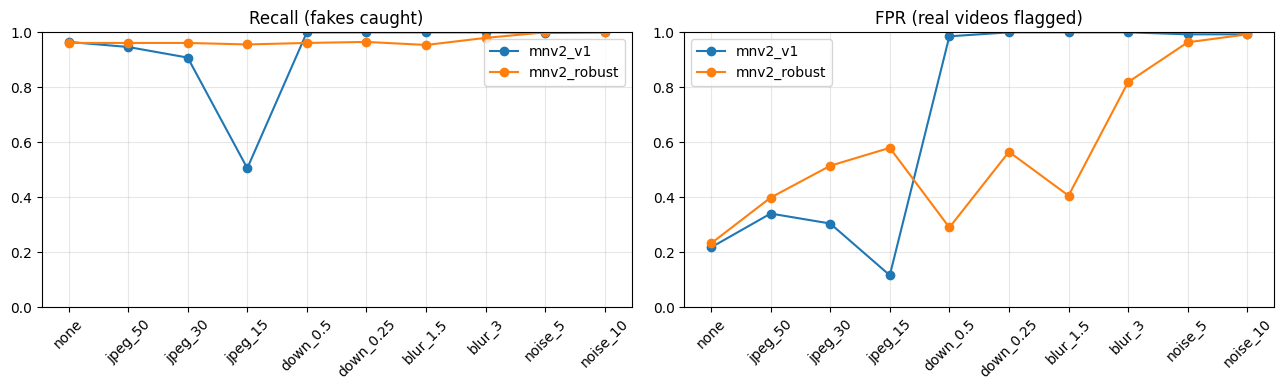

In [5]:
#@title 4 · Attack test: recall (fakes caught) and FPR (real videos flagged) under post-processing
import pandas as pd, matplotlib.pyplot as plt
from ffpp.robustness import attack_table
tables = []
for r in split_runs(ATTACK_RUNS):
    f = f"{RUNS_DIR}/{r}/eval/robustness_test.csv"
    tables.append(pd.read_csv(f) if os.path.exists(f) else attack_table(f"{RUNS_DIR}/{r}", LOCAL_CACHE))
att = pd.concat(tables, ignore_index=True)
att.to_csv(f"{REPORT_DIR}/robustness_all.csv", index=False)
display(att.pivot(index="attack", columns="run", values="recall").round(3).loc[att.attack.unique()])
display(att.pivot(index="attack", columns="run", values="fpr").round(3).loc[att.attack.unique()])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for r, g in att.groupby("run", sort=False):
    ax[0].plot(g.attack, g.recall, marker="o", label=r); ax[1].plot(g.attack, g.fpr, marker="o", label=r)
for a, t in zip(ax, ["Recall (fakes caught)", "FPR (real videos flagged)"]):
    a.set_title(t); a.tick_params(axis="x", rotation=45); a.set_ylim(0, 1); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(f"{REPORT_DIR}/robustness.png", dpi=150); plt.show()

In [6]:
#@title 5 · Quality slices: are false alarms concentrated in dark / low-contrast / blurry faces?
from ffpp.dataset import load_index
from ffpp.robustness import quality_features, quality_table
test_idx = load_index(LOCAL_CACHE, "test")
feats = quality_features(test_idx, LOCAL_CACHE)
feats.to_csv(f"{REPORT_DIR}/quality_features_test.csv", index=False)
rows = []
for r in [BASE_RUN, ROBUST_RUN]:
    pred = pd.read_csv(f"{RUNS_DIR}/{r}/eval/predictions_test.csv")
    thr = json.load(open(f"{RUNS_DIR}/{r}/eval/summary.json"))["threshold_from_val"]
    rows.append(quality_table(pred, feats, thr).assign(run=r))
qt = pd.concat(rows, ignore_index=True)
qt.to_csv(f"{REPORT_DIR}/quality_slices.csv", index=False)
display(qt.round(3))

,feature,bin,range,n_real,fpr,fpr_lo,fpr_hi,n_fake,recall,recall_lo,recall_hi,run
0,brightness,low,49.1–95.8,46,0.217,0.123,0.356,195,0.990,0.963,0.997,mnv2_v1
1,brightness,mid,95.8–114.4,46,0.174,0.091,0.307,169,0.970,0.933,0.987,mnv2_v1
2,brightness,high,114.5–200.4,46,0.261,0.156,0.403,180,0.933,0.887,0.961,mnv2_v1
3,contrast,low,27.7–45.6,46,0.196,0.107,0.332,193,0.933,0.888,0.960,mnv2_v1
4,contrast,mid,45.6–54.6,46,0.196,0.107,0.332,184,0.984,0.953,0.994,mnv2_v1
5,contrast,high,54.6–86.7,46,0.261,0.156,0.403,167,0.982,0.949,0.994,mnv2_v1
6,sharpness,low,1.1–1.8,46,0.348,0.227,0.492,220,0.982,0.954,0.993,mnv2_v1
7,sharpness,mid,1.8–2.0,46,0.174,0.091,0.307,175,0.954,0.912,0.977,mnv2_v1
8,sharpness,high,2.0–2.9,46,0.130,0.061,0.257,149,0.953,0.906,0.977,mnv2_v1
9,brightness,low,49.1–95.8,46,0.239,0.139,0.379,195,0.974,0.941,0.989,mnv2_robust


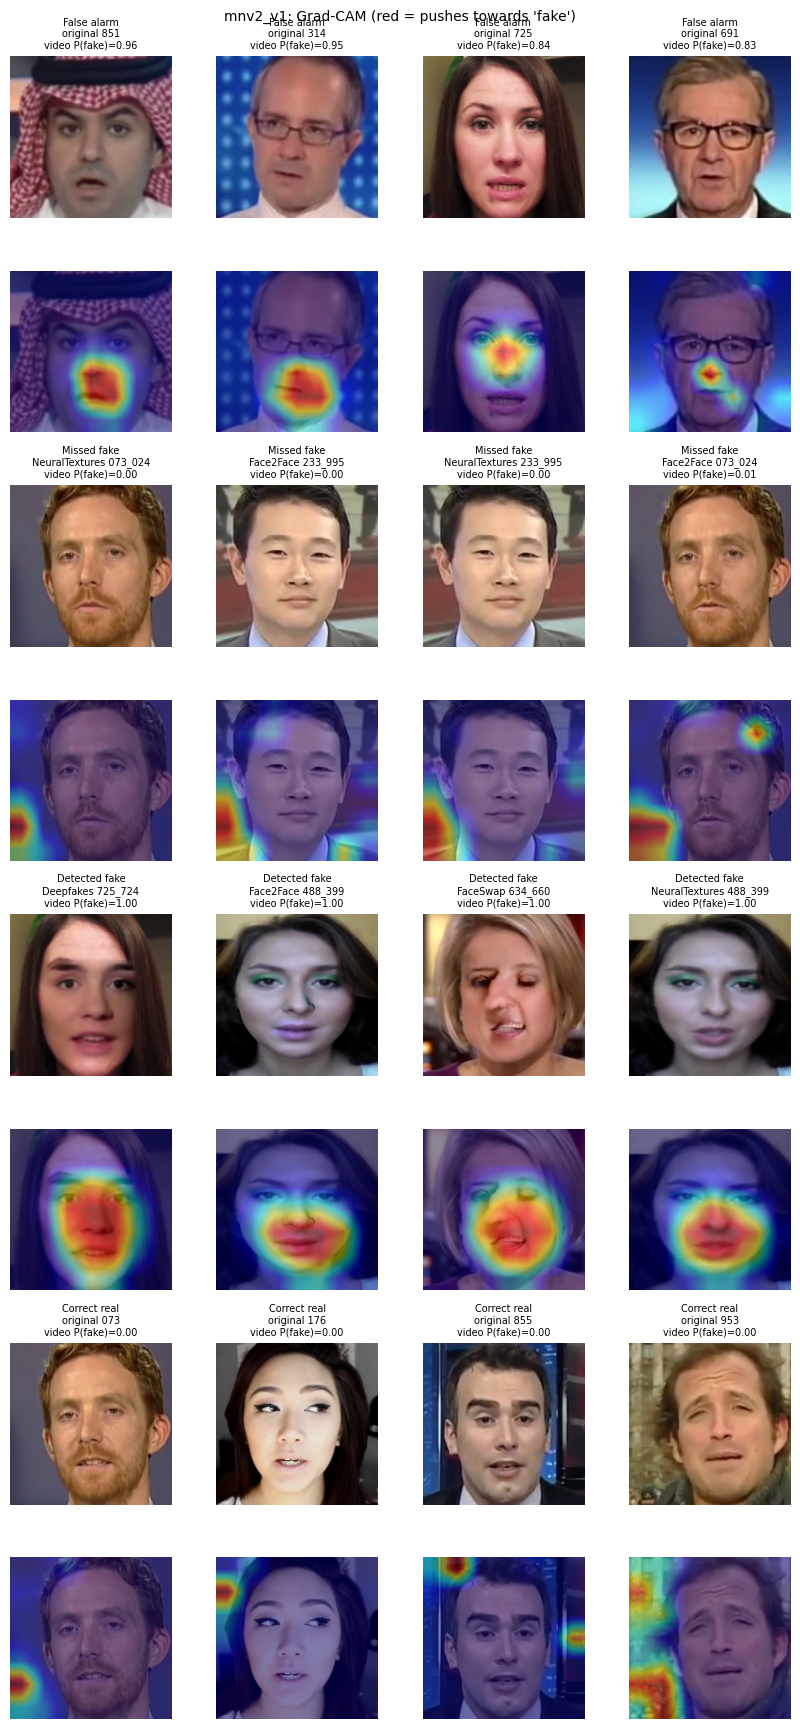

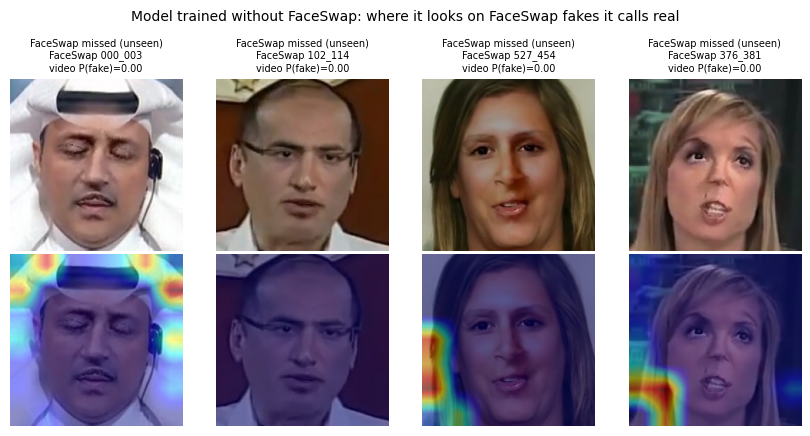

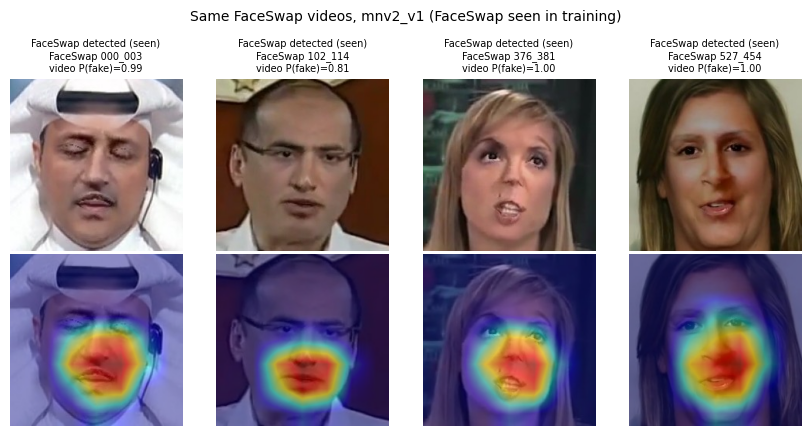

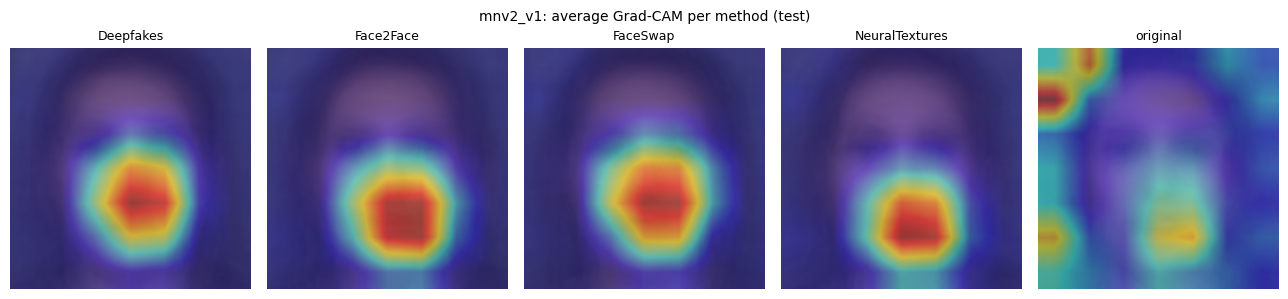

In [7]:
#@title 6 · Grad-CAM: errors, correct detections, and the average map per method
import numpy as np
from ffpp.train import load_trained
from ffpp.dataset import FrameCache
from ffpp.xai import explain_frames
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def mid_face(cache_file):
    fc = FrameCache(f"{LOCAL_CACHE}/{cache_file}"); return fc.frame(0, fc.T // 2)

def gallery(run, groups, fname, title):
    model, cfg, _ = load_trained(f"{RUNS_DIR}/{run}", "best", dev)
    groups = [(l, g) for l, g in groups if len(g)]
    if not groups:
        print("nothing to show for", fname); return
    n = max(len(g) for _, g in groups)
    fig, ax = plt.subplots(2 * len(groups), n, figsize=(2.1 * n, 4.4 * len(groups)))
    ax = np.atleast_2d(ax)
    for gi, (label, g) in enumerate(groups):
        for j in range(n):
            for k in (0, 1): ax[2 * gi + k, j].axis("off")
            if j >= len(g): continue
            row = g.iloc[j]
            face = mid_face(row.cache_file)
            ov, _, p = explain_frames(model, face[None], cfg["img_size"], False, dev)
            ax[2 * gi, j].imshow(face); ax[2 * gi + 1, j].imshow(ov[0])
            ax[2 * gi, j].set_title(f"{label}\n{row.method} {row.video_id.split('/')[-1]}\nvideo P(fake)={row.score:.2f}", fontsize=7)
    fig.suptitle(title, fontsize=10); plt.tight_layout()
    plt.savefig(f"{REPORT_DIR}/{fname}", dpi=150); plt.show()

idx_c = test_idx[["video_id", "cache_file"]]
base = pd.read_csv(f"{RUNS_DIR}/{BASE_RUN}/eval/predictions_test.csv").merge(idx_c, on="video_id")
thr = json.load(open(f"{RUNS_DIR}/{BASE_RUN}/eval/summary.json"))["threshold_from_val"]
fp = base[(base.label == 0) & (base.score >= thr)].nlargest(4, "score")
fn = base[(base.label == 1) & (base.score < thr)].nsmallest(4, "score")
tp = pd.concat([g.nlargest(1, "score") for _, g in base[base.label == 1].groupby("method")])
tn = base[base.label == 0].nsmallest(4, "score")
gallery(BASE_RUN, [("False alarm", fp), ("Missed fake", fn), ("Detected fake", tp), ("Correct real", tn)],
        "gradcam_errors.png", f"{BASE_RUN}: Grad-CAM (red = pushes towards 'fake')")
lomo = pd.read_csv(f"{RUNS_DIR}/mnv2_lomo_FS/eval/predictions_test.csv").merge(idx_c, on="video_id")
fs_miss = lomo[lomo.method == "FaceSwap"].nsmallest(4, "score")
gallery("mnv2_lomo_FS", [("FaceSwap missed (unseen)", fs_miss)], "gradcam_lomo_faceswap.png",
        "Model trained without FaceSwap: where it looks on FaceSwap fakes it calls real")
gallery(BASE_RUN, [("FaceSwap detected (seen)", base.merge(fs_miss[["video_id"]], on="video_id"))],
        "gradcam_base_faceswap.png", f"Same FaceSwap videos, {BASE_RUN} (FaceSwap seen in training)")

# average Grad-CAM per class/method over all test videos (middle frame of clip 1)
model, cfg, _ = load_trained(f"{RUNS_DIR}/{BASE_RUN}", "best", dev)
avg = {}
for m, g in base.groupby("method"):
    faces = np.stack([mid_face(c) for c in g.cache_file])
    cams = np.concatenate([explain_frames(model, faces[i:i + 32], cfg["img_size"], False, dev)[1]
                           for i in range(0, len(faces), 32)])
    avg[m] = (faces.mean(0).astype(np.uint8), cams.mean(0))
fig, ax = plt.subplots(1, len(avg), figsize=(2.6 * len(avg), 3))
from ffpp.xai import overlay
for a, (m, (face, cam)) in zip(ax, avg.items()):
    a.imshow(overlay(face, cam / cam.max())); a.set_title(m, fontsize=9); a.axis("off")
fig.suptitle(f"{BASE_RUN}: average Grad-CAM per method (test)", fontsize=10); plt.tight_layout()
plt.savefig(f"{REPORT_DIR}/gradcam_average.png", dpi=150); plt.show()
np.savez_compressed(f"{REPORT_DIR}/gradcam_average.npz", **{m: c for m, (f, c) in avg.items()})

In [8]:
#@title 7 · External test: FaceShifter (official FF++ release, never used for training)
from ffpp import download
from ffpp.data import build_manifest, load_official_meta, cross_split_ids
from ffpp.crops import extract_all
from ffpp.robustness import evaluate_external
split_of, youtube_of, _ = load_official_meta(META)
names = download.split_pairs(META, "test", exclude_ids=set(cross_split_ids(split_of, youtube_of)))
print(len(names), "FaceShifter test videos")
download.fetch(SCRIPT, "/content/fsh", [("FaceShifter", n) for n in names])
man = build_manifest("/content/fsh", META, methods=["FaceShifter"], skip=("deepfakedetection", "actors"))
print(man.groupby(["split", "method"]).size())
extract_all(man, EXT_CACHE)
ext = []
for r in split_runs(EXTERNAL_RUNS):
    if os.path.exists(f"{RUNS_DIR}/{r}/eval/summary.json"):
        ext.append(evaluate_external(f"{RUNS_DIR}/{r}", EXT_CACHE, LOCAL_CACHE))
ext = pd.DataFrame(ext)
ext.to_csv(f"{REPORT_DIR}/external_faceshifter.csv", index=False)
display(ext[["run", "roc_auc", "recall", "recall_lo", "recall_hi", "fpr", "n_fake", "n_real",
             "ffpp_test_roc_auc", "ffpp_test_recall"]].round(3))

136 FaceShifter test videos
136/136 videos in /content/fsh
split  method     
test   FaceShifter    136
dtype: int64
100/136 videos  (2.99 s/video, about 2 min left)
136/136 videos  (3.00 s/video, about 0 min left)


,run,roc_auc,recall,recall_lo,recall_hi,fpr,n_fake,n_real,ffpp_test_roc_auc,ffpp_test_recall
0,mnv2_v1,0.750,0.559,0.475,0.640,0.217,136,138,0.967,0.965
1,mnv2_robust,0.692,0.478,0.396,0.561,0.232,136,138,0.965,0.961
2,mnv2_gru_v1,0.657,0.463,0.382,0.547,0.246,136,138,0.976,0.976
3,mnv2_lomo_FS,0.716,0.478,0.396,0.561,0.217,136,138,0.832,0.765


In [9]:
#@title 8 · Demo videos for notebook 06 (test split only: none of them was seen in training)
os.makedirs(DEMO_DIR, exist_ok=True)
fsh = pd.read_csv(f"{RUNS_DIR}/{BASE_RUN}/eval/predictions_FaceShifter_test.csv")
fsh = fsh[fsh.label == 1]
pick = [("correct real", base[base.label == 0].nsmallest(2, "score")),
        ("false alarm", fp.head(2)),
        ("detected fake", tp),
        ("missed fake", fn.head(2)),
        ("FaceShifter detected", fsh.nlargest(1, "score")),
        ("FaceShifter missed", fsh.nsmallest(1, "score"))]
items, cat = [], []
for why, g in pick:
    for r in g.itertuples():
        ds, name = ("original", r.video_id) if r.method == "original" else (r.method, r.video_id.split("/")[-1])
        items.append((ds, name))
        cat.append(dict(file=f"{ds}_{name}.mp4", truth="real" if r.label == 0 else "fake", method=r.method,
                        why=why, base_score=round(r.score, 3)))
paths = download.fetch(SCRIPT, "/content/demo_dl", items)
import shutil
for (ds, name), c in zip(items, cat):
    src = next((p for p in paths if p.stem == name and ("original" if ds == "original" else ds) in str(p)), None)
    if src: shutil.copy2(src, f"{DEMO_DIR}/{c['file']}")
cat = pd.DataFrame(cat).drop_duplicates("file")
cat.to_csv(f"{DEMO_DIR}/catalog.csv", index=False)
display(cat)

12/12 videos in /content/demo_dl


,file,truth,method,why,base_score
0,original_073.mp4,real,original,correct real,0.000
1,original_176.mp4,real,original,correct real,0.000
2,original_851.mp4,real,original,false alarm,0.958
3,original_314.mp4,real,original,false alarm,0.950
4,Deepfakes_725_724.mp4,fake,Deepfakes,detected fake,1.000
5,Face2Face_488_399.mp4,fake,Face2Face,detected fake,1.000
6,FaceSwap_634_660.mp4,fake,FaceSwap,detected fake,1.000
7,NeuralTextures_488_399.mp4,fake,NeuralTextures,detected fake,1.000
8,NeuralTextures_073_024.mp4,fake,NeuralTextures,missed fake,0.001
9,Face2Face_233_995.mp4,fake,Face2Face,missed fake,0.002


In [10]:
#@title 9 · Pack all results for the report (JSON/CSV/PNG only; no weights, no videos)
import zipfile, glob
out = f"{DRIVE_ROOT}/results_final.zip"
with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob(f"{RUNS_DIR}/*/*.json") + glob.glob(f"{RUNS_DIR}/*/*.csv") + \
             glob.glob(f"{RUNS_DIR}/*/eval/*.json") + glob.glob(f"{RUNS_DIR}/*/eval/*.csv"):
        z.write(f, "runs/" + os.path.relpath(f, RUNS_DIR))
    for f in glob.glob(f"{REPORT_DIR}/*"):
        z.write(f, "report/" + os.path.basename(f))
    if os.path.exists(f"{DEMO_DIR}/catalog.csv"):
        z.write(f"{DEMO_DIR}/catalog.csv", "demo_videos/catalog.csv")
print(out, f"{os.path.getsize(out) / 1e6:.1f} MB")
from google.colab import files; files.download(out)

/content/drive/MyDrive/IS665_Deepfake/results_final.zip 5.7 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>